In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score,classification_report,confusion_matrix)
from PIL import Image
from pathlib import Path

In [1]:
from google.colab import files
uploaded = files.upload()

Saving PRAICP-1001-GenderDetc.zip to PRAICP-1001-GenderDetc.zip


In [2]:
import zipfile
zip_path = next(iter(uploaded.keys()))
extract_path = "/content/gender_dataset"
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

In [5]:
for root, dirs, files_list in os.walk(extract_path):
    if dirs:
        print(root, dirs[:10])

/content/gender_dataset ['Data']
/content/gender_dataset/Data ['gender_dataset_face']
/content/gender_dataset/Data/gender_dataset_face ['woman', 'man']


In [6]:
dataset_path = extract_path
male_folder = None
female_folder = None
for root, dirs, files_list in os.walk(extract_path):
    folder_names = {d.lower(): d for d in dirs}
    if "male" in folder_names and "female" in folder_names:
        dataset_path = root
        male_folder = os.path.join(root, folder_names["male"])
        female_folder = os.path.join(root, folder_names["female"])
        break
print("Dataset Path:", dataset_path)
print("Male Folder:", male_folder)
print("Female Folder:", female_folder)

Dataset Path: /content/gender_dataset
Male Folder: None
Female Folder: None


In [10]:
data = []
image_extensions = [".jpg", ".jpeg", ".png", ".bmp"]
male_folder = "/content/gender_dataset/Data/gender_dataset_face/man"
female_folder = "/content/gender_dataset/Data/gender_dataset_face/woman"
for label, folder in [("Male", male_folder), ("Female", female_folder)]:
    if folder and os.path.exists(folder):
        for file in os.listdir(folder):
            file_path = os.path.join(folder, file)
            if os.path.splitext(file)[1].lower() in image_extensions:
                try:
                    with Image.open(file_path) as img:
                        img.verify()
                    data.append({"image_path": file_path, "gender": label})
                except Exception:
                    print("Corrupted image skipped:", file_path)
    else:
        print(f"Directory does not exist: {folder}")

df = pd.DataFrame(data)
print("Total Images:", len(df))
if not df.empty:
    print(df.head())
else:
    print("No images found. Please check the paths.")

Total Images: 2307
                                          image_path gender
0  /content/gender_dataset/Data/gender_dataset_fa...   Male
1  /content/gender_dataset/Data/gender_dataset_fa...   Male
2  /content/gender_dataset/Data/gender_dataset_fa...   Male
3  /content/gender_dataset/Data/gender_dataset_fa...   Male
4  /content/gender_dataset/Data/gender_dataset_fa...   Male


In [12]:
print(df["gender"].value_counts())

gender
Male      1173
Female    1134
Name: count, dtype: int64


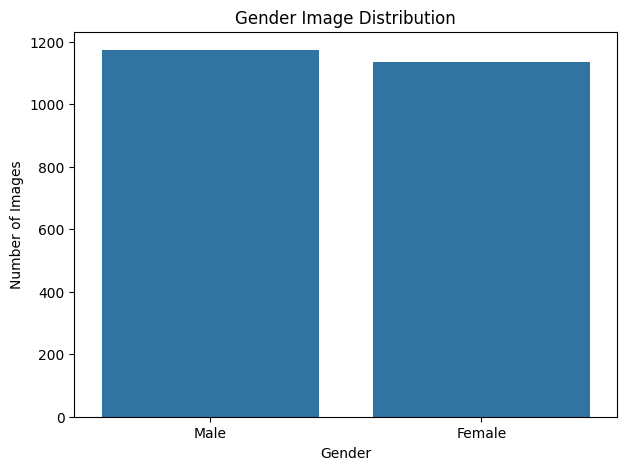

In [13]:
plt.figure(figsize=(7,5))
sns.countplot(data=df,x="gender")
plt.title("Gender Image Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Images")
plt.show()

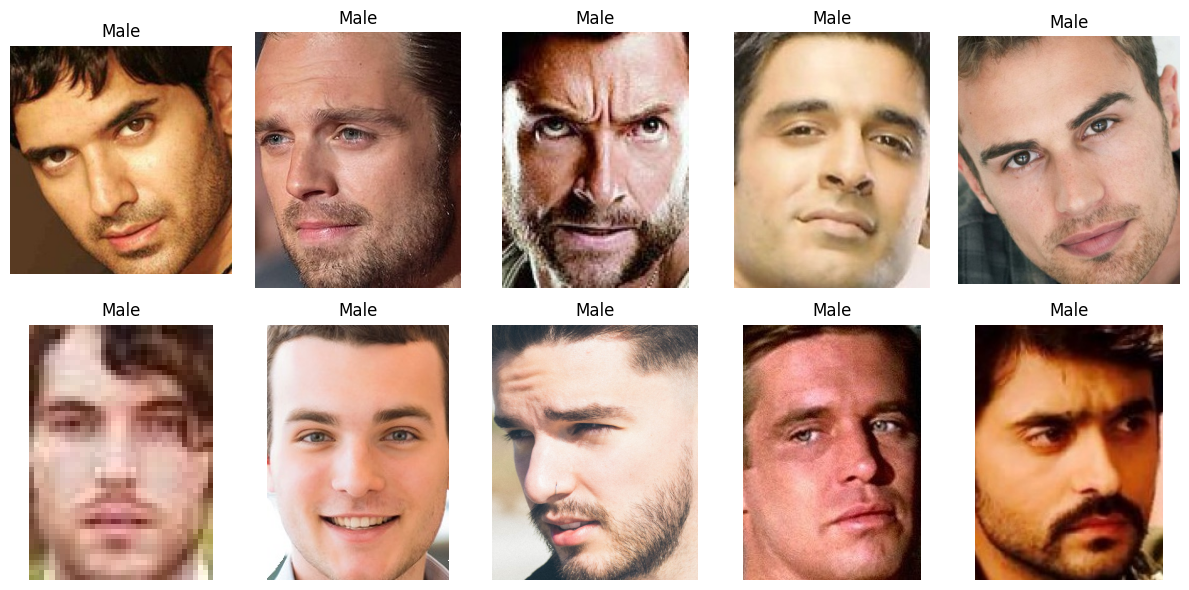

In [14]:
plt.figure(figsize=(12,6))
for i in range(10):
    image_path = df.iloc[i]["image_path"]
    label = df.iloc[i]["gender"]
    img = Image.open(image_path)
    plt.subplot(2,5,i+1)
    plt.imshow(img)
    plt.title(label)
    plt.axis("off")
plt.tight_layout()
plt.show()

In [15]:
train_df, temp_df = train_test_split( df,test_size=0.30,random_state=42,stratify=df["gender"])
val_df, test_df = train_test_split(temp_df,test_size=0.50,random_state=42,stratify=temp_df["gender"])
print("Training Images:", len(train_df))
print("Validation Images:", len(val_df))
print("Testing Images:", len(test_df))

Training Images: 1614
Validation Images: 346
Testing Images: 347


In [16]:
IMG_SIZE = 128
BATCH_SIZE = 32
class_names = ["Female", "Male"]
label_map = {"Female": 0,"Male": 1}
def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_image(image,channels=3,expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image,[IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

In [17]:
def create_dataset(dataframe, shuffle=False):
    paths = dataframe["image_path"].values
    labels = dataframe["gender"].map(label_map).values
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        dataset = dataset.shuffle(buffer_size=len(dataframe),seed=42)
    dataset = dataset.map(load_image,num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset
train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)
print("Preprocessing completed!")

Preprocessing completed!


In [18]:
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)])

In [19]:
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),data_augmentation,
    layers.Conv2D(32,(3,3), activation="relu" ),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(  64,(3,3),activation="relu"),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(  128,(3,3),activation="relu"),
    layers.MaxPooling2D(2,2),
    layers.Conv2D( 256,(3,3),activation="relu"),
    layers.MaxPooling2D(2,2),
    layers.Flatten(),
    layers.Dense(128,activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(  1, activation="sigmoid")])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,568,321 (5.98 MB)

 Trainable params: 1,568,321 (5.98 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"])

In [21]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001)
checkpoint = ModelCheckpoint(
    "best_gender_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max")

In [22]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stop,reduce_lr,checkpoint])

Epoch 1/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 109s 2s/step - accuracy: 0.5248 - loss: 0.6954 - val_accuracy: 0.5751 - val_loss: 0.6850 - learning_rate: 0.0010
Epoch 2/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 73s 1s/step - accuracy: 0.6159 - loss: 0.6519 - val_accuracy: 0.8006 - val_loss: 0.4570 - learning_rate: 0.0010
Epoch 3/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 81s 1s/step - accuracy: 0.7546 - loss: 0.5235 - val_accuracy: 0.8179 - val_loss: 0.4654 - learning_rate: 0.0010
Epoch 4/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.8098 - loss: 0.4527 - val_accuracy: 0.8121 - val_loss: 0.3877 - learning_rate: 0.0010
Epoch 5/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 81s 1s/step - accuracy: 0.8092 - loss: 0.4294 - val_accuracy: 0.8671 - val_loss: 0.3194 - learning_rate: 0.0010
Epoch 6/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.8234 - loss: 0.4046 - val_accuracy: 0.8786 - val_loss: 0.2883 - learning_rate: 0.0010
Epoch 7/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 71s 1s/step - accuracy: 0.8346 - loss: 0.3898 - val_accuracy:

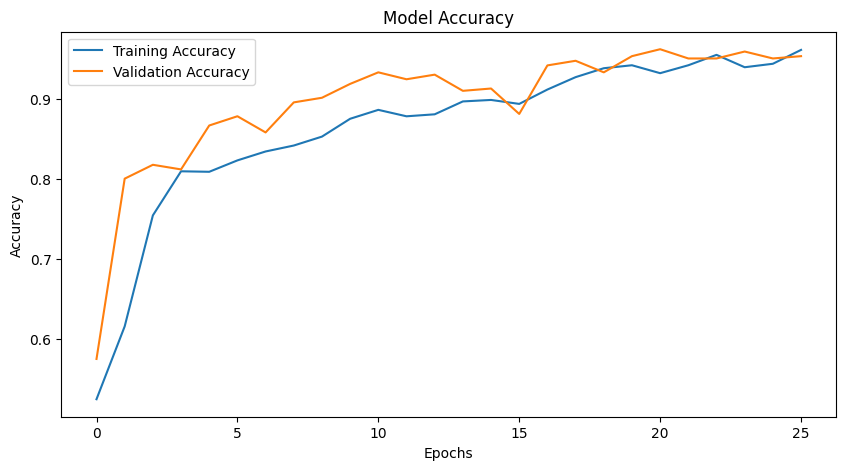

In [23]:
plt.figure(figsize=(10,5))
plt.plot( history.history["accuracy"],
    label="Training Accuracy")
plt.plot(history.history["val_accuracy"],
    label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

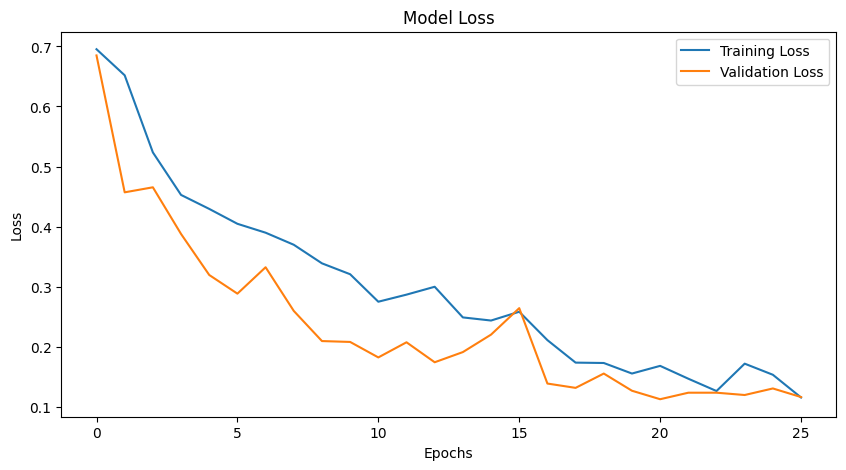

In [24]:
plt.figure(figsize=(10,5))
plt.plot(
    history.history["loss"],
    label="Training Loss")
plt.plot(
    history.history["val_loss"],
    label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [25]:
test_loss, test_accuracy = model.evaluate(test_ds)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 400ms/step - accuracy: 0.9424 - loss: 0.1387
Test Loss: 0.13865940272808075
Test Accuracy: 94.23630833625793 %


In [27]:
y_true = []
y_pred = []
for images, labels in test_ds:
    predictions = model.predict(
        images,
        verbose=0)
    predicted_labels = (predictions >= 0.5).astype(int).flatten()
    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)
print(classification_report(
    y_true,
    y_pred,
    target_names=["Female", "Male"]))

              precision    recall  f1-score   support

      Female       0.95      0.94      0.94       171
        Male       0.94      0.95      0.94       176

    accuracy                           0.94       347
   macro avg       0.94      0.94      0.94       347
weighted avg       0.94      0.94      0.94       347



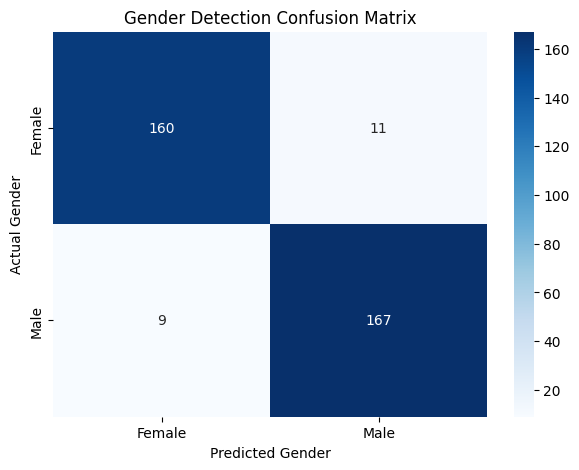

In [28]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Female", "Male"],
    yticklabels=["Female", "Male"])
plt.title("Gender Detection Confusion Matrix")
plt.xlabel("Predicted Gender")
plt.ylabel("Actual Gender")
plt.show()

In [29]:
model.save("gender_detection_model.keras")
print("Model saved successfully!")

Model saved successfully!


In [30]:
from google.colab import files
uploaded_image = files.upload()
image_path = next(iter(uploaded_image.keys()))

Saving Screenshot 2025-09-14 145339.png to Screenshot 2025-09-14 145339.png


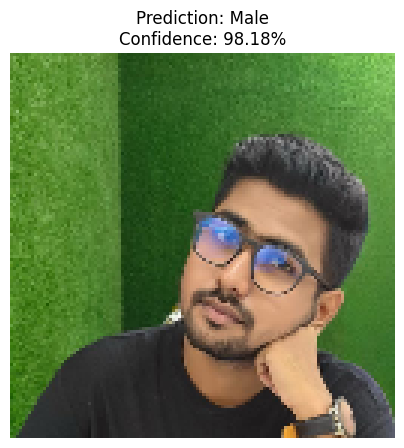

Predicted Gender: Male
Confidence: 98.18 %


In [31]:
def predict_gender(image_path):
    img = tf.keras.utils.load_img(
        image_path,
        target_size=(128,128)
    )

    img_array = tf.keras.utils.img_to_array(img)

    img_array = img_array / 255.0

    img_array = np.expand_dims(
        img_array,
        axis=0
    )

    prediction = model.predict(
        img_array,
        verbose=0
    )[0][0]

    if prediction >= 0.5:
        gender = "Male"
        confidence = prediction * 100

    else:
        gender = "Female"
        confidence = (1 - prediction) * 100

    plt.figure(figsize=(5,5))
    plt.imshow(img)
    plt.axis("off")
    plt.title(
        f"Prediction: {gender}\nConfidence: {confidence:.2f}%"
    )
    plt.show()

    print("Predicted Gender:", gender)
    print("Confidence:", round(confidence, 2), "%")

predict_gender(image_path)

In [32]:
import tensorflow as tf
model = tf.keras.models.load_model("gender_detection_model.keras")
print("Gender Detection Model Loaded Successfully!")

Gender Detection Model Loaded Successfully!
